# 03 — Risultati: confronto fra strategie

Stessa simulazione sul test set (2 ottobre 2017 – 3 febbraio 2018, 125 giorni) con cinque strategie. Il notebook legge i risultati di `python -m microgrid.evaluate`.

- **Nessuna batteria**: il fotovoltaico copre il carico, il resto va alla rete o viene dalla rete.
- **Regola ingenua**: la batteria carica quando c'è surplus solare e scarica quando c'è deficit. Non usa previsioni né prezzi.
- **Previsione + MILP**: il piano calcolato sulle previsioni è eseguito alla lettera; l'errore di previsione è assorbito dalla rete.
- **Previsione + MILP + correzione**: si segue lo scambio con la rete previsto dal piano; l'errore di previsione è assorbito dalla batteria, finché può. La regola di correzione è stata scelta sul periodo di validazione.
- **Previsione perfetta + MILP**: il piano è calcolato sui valori reali. È il riferimento teorico.

Tariffa: si acquista al prezzo day-ahead più 0,20 €/kWh di oneri, si vende al prezzo day-ahead.

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from microgrid.config import load_config, resolve_path
from microgrid.evaluate import COMPARISON_FILE, DAILY_FILE, PARETO_FILE, SENSITIVITY_FILE, STRATEGIES
from microgrid.plotting import COLORS, STRATEGY_STYLES, TEXT_SECONDARY, apply_style

apply_style()
config = load_config()
results_dir = resolve_path(config["paths"]["results"])
comparison = pd.read_csv(results_dir / COMPARISON_FILE, index_col="strategy")
daily = pd.read_csv(results_dir / DAILY_FILE, index_col="day", parse_dates=True)
front = pd.read_csv(results_dir / PARETO_FILE)
sweep = pd.read_csv(results_dir / SENSITIVITY_FILE)
main = comparison.loc[list(STRATEGIES)]
with_battery = [name for name in STRATEGIES if name != "no_battery"]
euro = lambda value: f"{value:,.0f}".replace(",", " ")
print(f"{len(daily)} giorni, {len(comparison)} strategie")

125 giorni, 6 strategie


## 1. Costo ed emissioni

`saving_captured` è il risparmio di costo diviso per quello della previsione perfetta. L'ultima riga è una variante: come *Previsione + MILP + correzione*, ma con la previsione ingenua del carico al posto del modello.

In [2]:
columns = {"description": "strategia", "cost_eur": "costo (€)", "emissions_kg": "emissioni (kgCO₂)",
           "cost_saving_pct": "risparmio costo (%)", "emissions_saving_pct": "risparmio emissioni (%)",
           "saving_captured": "quota del risparmio teorico", "battery_cycles": "cicli",
           "soc_end_kwh": "energia finale (kWh)", "residual_value_eur": "valore energia residua (€)"}
table = comparison[list(columns)].rename(columns=columns).set_index("strategia")
table.round({"costo (€)": 0, "emissioni (kgCO₂)": 0, "risparmio costo (%)": 1, "risparmio emissioni (%)": 1,
             "quota del risparmio teorico": 2, "cicli": 1, "energia finale (kWh)": 0, "valore energia residua (€)": 1})

,costo (€),emissioni (kgCO₂),risparmio costo (%),risparmio emissioni (%),quota del risparmio teorico,cicli,energia finale (kWh),valore energia residua (€)
strategia,,,,,,,,
Nessuna batteria,6069.0,10496.0,0.0,0.0,0.00,0.0,100.0,0.0
Regola ingenua,4691.0,7878.0,22.7,24.9,0.94,44.5,20.0,-17.7
Previsione + MILP,5554.0,9527.0,8.5,9.2,0.35,65.6,100.0,-0.0
Previsione + MILP + correzione,4842.0,8208.0,20.2,21.8,0.84,74.5,20.0,-17.7
Previsione perfetta + MILP,4602.0,7802.0,24.2,25.7,1.00,76.6,100.0,-0.0
Previsione ingenua del carico + MILP + correzione,4869.0,8249.0,19.8,21.4,0.82,72.0,27.0,-16.1


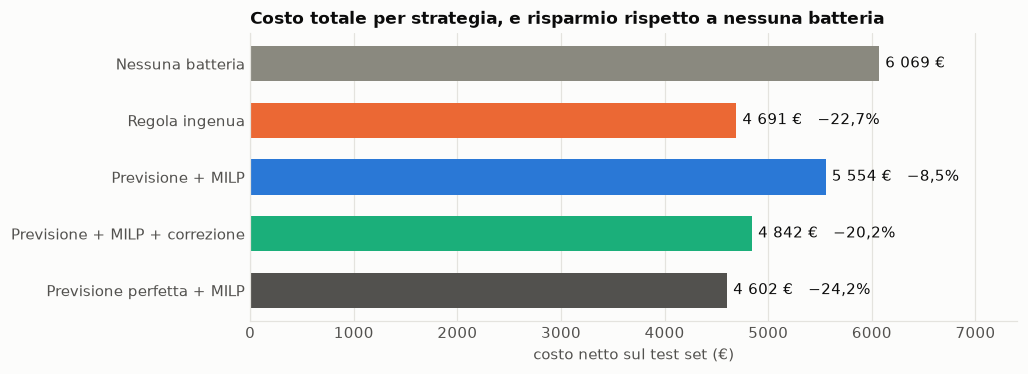

In [3]:
fig, ax = plt.subplots(figsize=(9, 3.4))
positions = np.arange(len(main))[::-1]
for position, (name, row) in zip(positions, main.iterrows()):
    ax.barh(position, row["cost_eur"], height=0.62, color=STRATEGY_STYLES[name]["color"])
    label = f"{euro(row['cost_eur'])} €" + ("" if name == "no_battery" else f"   −{row['cost_saving_pct']:.1f}%".replace(".", ","))
    ax.text(row["cost_eur"] + 60, position, label, va="center", fontsize=9.5)
ax.set_yticks(positions, main["description"])
ax.set_xlim(0, main["cost_eur"].max() * 1.22)
ax.set_xlabel("costo netto sul test set (€)")
ax.set_title("Costo totale per strategia, e risparmio rispetto a nessuna batteria")
ax.grid(axis="y", visible=False)
plt.show()

**Cosa si vede**

- **La regola ingenua batte il sistema previsione + ottimizzazione.** Risparmia il 22,7% contro l'8,5% del piano eseguito alla lettera e il 20,2% del piano con correzione. Ottiene il 94% del risparmio teorico senza usare né previsioni né prezzi.
- **Eseguire il piano alla lettera costa caro.** Ogni kWh di errore di previsione finisce sulla rete: acquistato a circa 0,23 €/kWh se manca, venduto a circa 0,03 €/kWh se avanza. La batteria fa 66 cicli ma lascia sul tavolo due terzi del risparmio possibile.
- **La correzione in tempo reale recupera quasi tutto**: da 5 554 € a 4 842 €. Resta 152 € sopra la regola ingenua.
- **Lo spazio per l'ottimizzazione è piccolo.** Fra regola ingenua e previsione perfetta ci sono 89 € su 125 giorni (107 € contando l'energia residua): meno del 2% del costo senza batteria. Con oneri di 0,20 €/kWh conta quasi solo l'autoconsumo, e per massimizzarlo basta la regola ingenua.
- **Energia residua.** Regola ingenua e piano con correzione finiscono con la batteria al minimo (20 kWh), le strategie MILP senza correzione a 100 kWh: gli 80 kWh di differenza valgono circa 18 €. Non cambia la classifica.
- **Variante con carico ingenuo.** Usare la previsione ingenua del carico al posto del modello costa 26 € in più: per questo problema le due previsioni del carico si equivalgono.
- Le emissioni seguono il costo: meno si acquista, meno si emette.

## 2. Risparmio accumulato nel tempo

Differenza cumulata fra il costo senza batteria e il costo di ogni strategia.

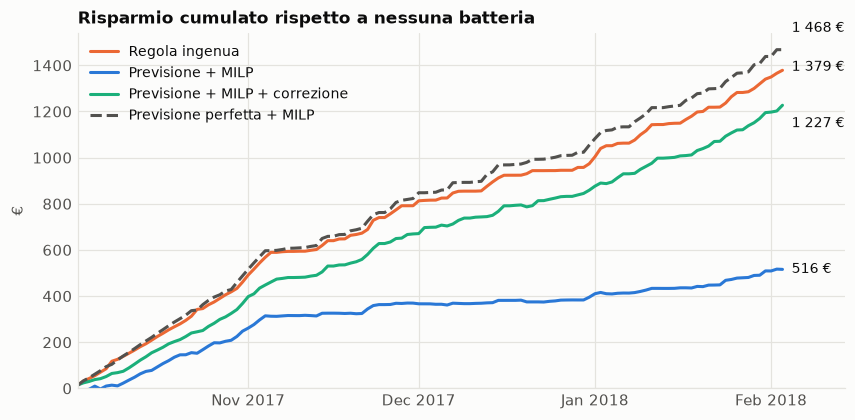

,Nessuna batteria,Regola ingenua,Previsione + MILP,Previsione + MILP + correzione,Previsione perfetta + MILP
day,,,,,
2017-10,420.0,-40.0,172.0,52.0,-67.0
2017-11,1633.0,1302.0,1511.0,1331.0,1298.0
2017-12,2091.0,1909.0,2065.0,1901.0,1860.0
2018-01,1743.0,1377.0,1629.0,1407.0,1359.0
2018-02,182.0,144.0,175.0,150.0,153.0


In [4]:
saving = daily[with_battery].rsub(daily["no_battery"], axis=0).cumsum()
fig, ax = plt.subplots(figsize=(9, 4.2))
offsets = {"perfect": 14, "rule": 2, "milp_corrected": -12, "milp": 0}
for name in with_battery:
    ax.plot(saving.index, saving[name], label=STRATEGIES[name], **STRATEGY_STYLES[name])
    ax.annotate(f"{euro(saving[name].iloc[-1])} €", (saving.index[-1], saving[name].iloc[-1]),
                xytext=(6, offsets[name]), textcoords="offset points", va="center", fontsize=9)
ax.set_xlim(saving.index[0], saving.index[-1] + pd.Timedelta(days=11))
ax.set_ylim(0, None)
ax.set_ylabel("€")
ax.set_title("Risparmio cumulato rispetto a nessuna batteria")
ax.xaxis.set_major_locator(mdates.MonthLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%b %Y"))
ax.legend(loc="upper left", fontsize=9)
plt.show()

monthly = daily[list(STRATEGIES)].groupby(daily.index.to_period("M")).sum()
monthly.columns = [STRATEGIES[name] for name in monthly.columns]
monthly.round(0)

**Cosa si vede**

- Il risparmio si accumula in ottobre, novembre e gennaio. A dicembre, con poco fotovoltaico, tutte le strategie risparmiano poco (182 € la regola ingenua): la batteria ha poco da accumulare.
- Il piano eseguito alla lettera resta indietro fin dalla prima settimana e non recupera mai.
- Regola ingenua e piano con correzione procedono quasi insieme. A dicembre il piano con correzione è leggermente davanti (1 901 € contro 1 909 €); nei mesi con più sole è la regola ingenua a prevalere.
- Il piano con correzione costa meno della regola ingenua in 58 giorni su 125.

## 3. Quanto costa l'errore di previsione

Il costo in più di un giorno è la differenza fra *Previsione + MILP* e *Previsione perfetta + MILP*. Le due strategie chiudono ogni giorno con la batteria allo stesso livello, quindi i giorni sono confrontabili uno a uno.

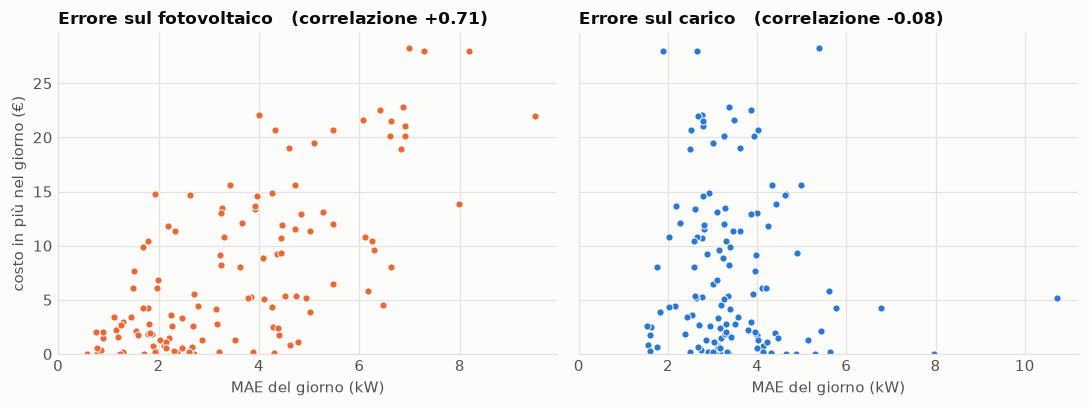

Costo in più totale: 952 €   media 7.62 €/giorno   mediana 5.18   massimo 28.21
I 25 giorni peggiori (20%) fanno il 52% del totale


,previsione + MILP (€),perfetta + MILP (€),costo in più (€),MAE carico (kW),MAE fotovoltaico (kW),errore carico (kWh),errore fotovoltaico (kWh)
2017-12-13,36.6,8.4,28.2,5.4,7.0,99.6,-138.1
2017-12-01,64.7,36.8,28.0,2.6,7.3,-3.7,-131.0
2017-10-06,25.9,-2.0,28.0,1.9,8.2,-2.6,132.6
2017-12-07,33.5,10.6,22.8,3.4,6.9,25.1,-157.1
2017-11-27,42.3,19.8,22.5,3.9,6.4,-11.2,-103.3


In [5]:
extra = (daily["milp"] - daily["perfect"]).rename("costo in più (€)")
fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
panels = [("pv_mae_kw", "pv", "Errore sul fotovoltaico"), ("load_mae_kw", "load", "Errore sul carico")]
for ax, (column, color, title) in zip(axes, panels):
    ax.scatter(daily[column], extra, s=22, color=COLORS[color], edgecolor="white", linewidth=0.6)
    ax.set_xlabel("MAE del giorno (kW)")
    ax.set_xlim(0, None)
    ax.set_title(f"{title}   (correlazione {extra.corr(daily[column]):+.2f})")
axes[0].set_ylabel("costo in più nel giorno (€)")
axes[0].set_ylim(0, None)
fig.tight_layout()
plt.show()

print(f"Costo in più totale: {extra.sum():.0f} €   media {extra.mean():.2f} €/giorno   mediana {extra.median():.2f}   massimo {extra.max():.2f}")
print(f"I 25 giorni peggiori (20%) fanno il {extra.nlargest(25).sum() / extra.sum():.0%} del totale")
worst = daily.loc[extra.nlargest(5).index, ["milp", "perfect", "load_mae_kw", "pv_mae_kw", "load_error_kwh", "pv_error_kwh"]]
worst.insert(2, "costo in più (€)", extra)
worst.index = worst.index.date
worst.rename(columns={"milp": "previsione + MILP (€)", "perfect": "perfetta + MILP (€)", "load_mae_kw": "MAE carico (kW)",
                      "pv_mae_kw": "MAE fotovoltaico (kW)", "load_error_kwh": "errore carico (kWh)",
                      "pv_error_kwh": "errore fotovoltaico (kWh)"}).round(1)

**Cosa si vede**

- L'errore di previsione costa 952 € in 125 giorni: 7,6 € al giorno in media, mai meno di zero, al massimo 28 €.
- **Conta l'errore sul fotovoltaico, non quello sul carico.** Il costo in più cresce con l'errore sul fotovoltaico (correlazione +0,71: circa 2,7 € per ogni kW di MAE) ed è indipendente da quello sul carico (−0,08). Il fotovoltaico ha errori molto più grandi in energia: nei giorni peggiori oltre 100 kWh.
- Non ci sono giorni catastrofici: i 25 giorni peggiori fanno circa metà del totale. La perdita è diffusa, non concentrata.
- Nei giorni peggiori l'errore va in entrambe le direzioni: sole previsto e non arrivato (6 ottobre: la batteria carica dalla rete) oppure sole arrivato e non previsto (1, 7 e 13 dicembre: il surplus non pianificato si vende a poco).
- Migliorare la previsione del carico non servirebbe a nulla; servirebbe una previsione migliore del fotovoltaico, che qui è già ottimistica perché usa il meteo reale.

## 4. Fronte di Pareto costo–emissioni

La simulazione è ripetuta con pesi `λ` crescenti sulle emissioni. Ogni pannello ha la stessa ampiezza degli assi (400 kgCO₂ e 120 €), così le tre curve sono confrontabili.

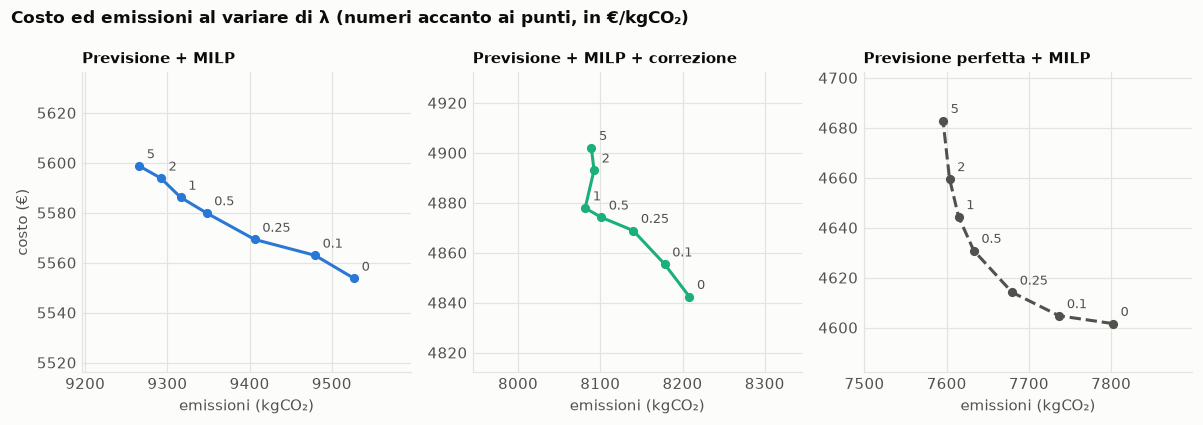

cost_eur                        emissions_kg  \
strategy                 milp milp_corrected perfect         milp   
carbon_weight_eur_kg                                                
0.00                   5554.0         4842.0  4602.0       9527.0   
0.10                   5563.0         4855.0  4605.0       9480.0   
0.25                   5569.0         4869.0  4614.0       9406.0   
0.50                   5580.0         4874.0  4631.0       9348.0   
1.00                   5586.0         4878.0  4644.0       9316.0   
2.00                   5594.0         4893.0  4660.0       9292.0   
5.00                   5599.0         4902.0  4683.0       9266.0   

                                             
strategy             milp_corrected perfect  
carbon_weight_eur_kg                         
0.00                         8208.0  7802.0  
0.10                         8178.0  7737.0  
0.25                         8140.0  7680.0  
0.50                         8101.0  7633.0  
1.00                         8082.0  7614.0  
2.00                         8092.0  7603.0  
5.00                         8089.0  7596.0

In [6]:
names = ["milp", "milp_corrected", "perfect"]
fig, axes = plt.subplots(1, 3, figsize=(11, 3.9))
for ax, name in zip(axes, names):
    curve = front[front["strategy"] == name]
    ax.plot(curve["emissions_kg"], curve["cost_eur"], marker="o", markersize=5, **STRATEGY_STYLES[name])
    for row in curve.itertuples():
        ax.annotate(f"{row.carbon_weight_eur_kg:g}", (row.emissions_kg, row.cost_eur), xytext=(5, 5),
                    textcoords="offset points", fontsize=8.5, color=TEXT_SECONDARY)
    x_mid = (curve["emissions_kg"].min() + curve["emissions_kg"].max()) / 2
    y_mid = (curve["cost_eur"].min() + curve["cost_eur"].max()) / 2
    ax.set_xlim(x_mid - 200, x_mid + 200)
    ax.set_ylim(y_mid - 60, y_mid + 60)
    ax.set_xlabel("emissioni (kgCO₂)")
    ax.set_title(STRATEGIES[name], fontsize=10)
axes[0].set_ylabel("costo (€)")
fig.suptitle("Costo ed emissioni al variare di λ (numeri accanto ai punti, in €/kgCO₂)", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
plt.show()

pivot = front.pivot(index="carbon_weight_eur_kg", columns="strategy", values=["cost_eur", "emissions_kg"])
pivot.round(0)

**Cosa si vede**

- **Il compromesso esiste ma è piccolo.** Con previsione perfetta, passare da `λ` = 0 a `λ` = 5 €/kgCO₂ riduce le emissioni del 2,6% (da 7 802 a 7 596 kg) e aumenta il costo dell'1,8% (da 4 602 a 4 683 €).
- Il grosso del guadagno arriva subito: a `λ` = 1 si è già a 7 614 kg con 43 € in più, cioè circa 230 € per tonnellata di CO₂ evitata. Oltre, la curva è quasi verticale.
- Con le previsioni vere la forma è la stessa, spostata verso costi ed emissioni più alti. Con la correzione la curva non è monotona: oltre `λ` = 1 le emissioni risalgono leggermente, perché la batteria non segue più esattamente il piano.
- Il motivo è lo stesso della sezione 1: le emissioni dipendono soprattutto da quanta energia si acquista, non da quando. Spostare gli acquisti verso le ore pulite muove poco.

## 5. Analisi di sensitività

Si cambia un parametro alla volta; gli altri restano ai valori di default (batteria 200 kWh e 50 kW, fotovoltaico 100 kWp, oneri 0,20 €/kWh). La potenza della batteria non cambia con la capacità.

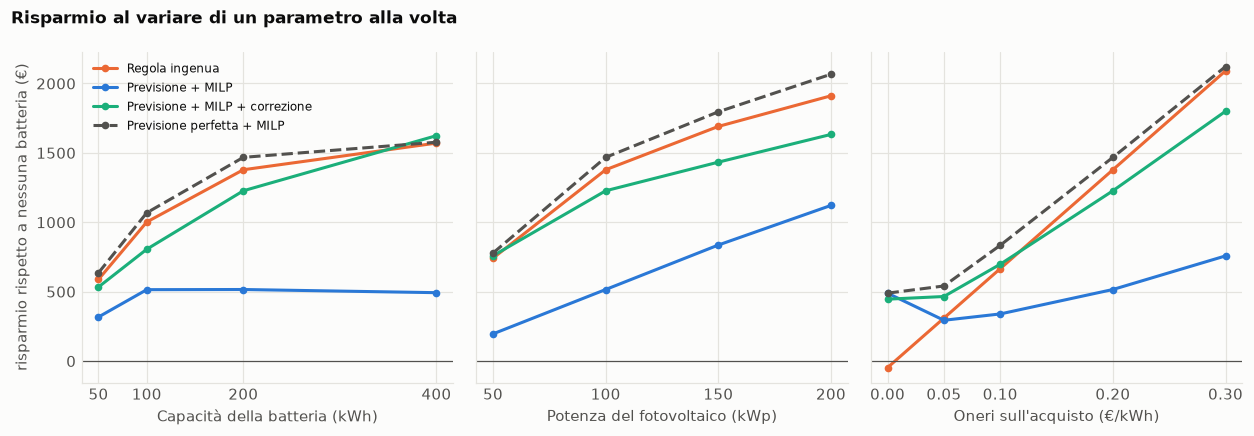

strategy                         Regola ingenua  Previsione + MILP  \
parameter                value                                       
battery_capacity_kwh     50.00            588.0              318.0   
                         100.00          1002.0              515.0   
                         200.00          1379.0              516.0   
                         400.00          1571.0              493.0   
import_surcharge_eur_kwh 0.00             -47.0              489.0   
                         0.05             310.0              294.0   
                         0.10             666.0              340.0   
                         0.20            1379.0              516.0   
                         0.30            2091.0              758.0   
pv_peak_kw               50.00            742.0              196.0   
                         100.00          1379.0              516.0   
                         150.00          1691.0              836.0   
                         200.00          1911.0             1122.0   

strategy                         Previsione + MILP + correzione  \
parameter                value                                    
battery_capacity_kwh     50.00                            534.0   
                         100.00                           806.0   
                         200.00                          1227.0   
                         400.00                          1624.0   
import_surcharge_eur_kwh 0.00                             446.0   
                         0.05                             465.0   
                         0.10                             698.0   
                         0.20                            1227.0   
                         0.30                            1800.0   
pv_peak_kw               50.00                            759.0   
                         100.00                          1227.0   
                         150.00                          1433.0   
                         200.00                          1633.0   

strategy                         Previsione perfetta + MILP  
parameter                value                               
battery_capacity_kwh     50.00                        636.0  
                         100.00                      1068.0  
                         200.00                      1468.0  
                         400.00                      1577.0  
import_surcharge_eur_kwh 0.00                         489.0  
                         0.05                         541.0  
                         0.10                         834.0  
                         0.20                        1468.0  
                         0.30                        2122.0  
pv_peak_kw               50.00                        779.0  
                         100.00                      1468.0  
                         150.00                      1796.0  
                         200.00                      2067.0

In [7]:
panels = [("battery_capacity_kwh", "Capacità della batteria (kWh)"), ("pv_peak_kw", "Potenza del fotovoltaico (kWp)"),
          ("import_surcharge_eur_kwh", "Oneri sull'acquisto (€/kWh)")]
fig, axes = plt.subplots(1, 3, figsize=(11.5, 4), sharey=True)
for ax, (parameter, title) in zip(axes, panels):
    part = sweep[sweep["parameter"] == parameter]
    for name in with_battery:
        curve = part[part["strategy"] == name]
        ax.plot(curve["value"], curve["cost_saving_eur"], marker="o", markersize=4, label=STRATEGIES[name], **STRATEGY_STYLES[name])
    ax.set_xticks(sorted(part["value"].unique()))
    ax.axhline(0, color=TEXT_SECONDARY, linewidth=0.8)
    ax.set_xlabel(title)
axes[0].set_ylabel("risparmio rispetto a nessuna batteria (€)")
axes[0].legend(loc="upper left", fontsize=8)
fig.suptitle("Risparmio al variare di un parametro alla volta", x=0.01, ha="left", fontsize=11, fontweight="bold")
fig.tight_layout()
plt.show()

view = sweep[sweep["strategy"] != "no_battery"].pivot(index=["parameter", "value"], columns="strategy", values="cost_saving_eur")
view[with_battery].rename(columns=STRATEGIES).round(0)

**Cosa si vede**

- **Capacità della batteria.** Il risparmio cresce con la capacità ma sempre meno: da 100 a 200 kWh la regola ingenua guadagna 377 €, da 200 a 400 kWh solo 192 €. Il piano eseguito alla lettera resta fermo a circa 500 € con qualunque capacità: più batteria significa più energia mossa sulla base di previsioni sbagliate.
- **Potenza del fotovoltaico.** Più sole c'è, più la batteria rende, per tutte le strategie. Con 50 kWp il piano con correzione supera di poco la regola ingenua (759 € contro 742 €).
- **Oneri sull'acquisto: è il parametro che decide chi vince.**
  - Con oneri nulli conta solo l'arbitraggio sui prezzi: il MILP azzera quasi il costo (da 496 a 7 €), la regola ingenua **perde** 47 € rispetto a non avere la batteria. Ma le emissioni del MILP raddoppiano (19 509 kg contro 10 496), perché compra e rivende energia di rete.
  - Con 0,05 €/kWh il piano con correzione risparmia 465 €, la regola ingenua 310 €.
  - Con 0,10 €/kWh sono alla pari (698 € contro 666 €).
  - Da 0,20 €/kWh in su vince la regola ingenua.
- **La previsione perfetta non è un limite superiore assoluto.** Con 400 kWh regola ingenua e piano con correzione la raggiungono o la superano. Il MILP pianifica un giorno alla volta e deve chiudere ogni giorno al livello di partenza; le altre due strategie possono portare energia da un giorno all'altro e finiscono il periodo con la batteria più scarica.

## Conclusioni

- **Risposta alla domanda del progetto.** Con la tariffa di riferimento, previsione + ottimizzazione **non** fa risparmiare rispetto a una regola semplice: 20,2% contro 22,7% nel caso migliore, 8,5% eseguendo il piano alla lettera. Rispetto a non avere la batteria risparmia; rispetto alla regola ingenua no.
- **Perché.** Con 0,20 €/kWh di oneri sull'acquisto, un kWh autoconsumato vale circa sette volte la differenza di prezzo tipica fra le ore di un giorno. L'obiettivo diventa massimizzare l'autoconsumo, e per farlo basta reagire al surplus reale: non serve prevederlo. Lo spazio fra regola ingenua e previsione perfetta è meno del 2% del costo.
- **Quando l'ottimizzazione serve.** Con oneri bassi (fino a 0,10 €/kWh) il valore sta nell'arbitraggio sui prezzi, che la regola ingenua non vede: lì il MILP vince, e con oneri nulli è l'unica strategia che guadagna.
- **Come si esegue il piano conta più di come lo si calcola.** Far assorbire l'errore di previsione alla batteria invece che alla rete vale 711 €: tre quarti di ciò che darebbe una previsione perfetta (952 €).
- **L'errore che costa è quello sul fotovoltaico**, non quello sul carico.
- **Emissioni.** Pesare le emissioni nell'obiettivo le riduce al più del 2–3%: dipendono da quanta energia si acquista, non da quando.

Limiti di questi risultati: il test set copre solo autunno e inverno; il meteo usato per prevedere il fotovoltaico è quello reale; la tariffa è una semplificazione; la regola di correzione è stata scelta sulla validazione ma il confronto finale è su un solo periodo di 125 giorni.